# 06 · Experiment E6 — the safe Age-of-Information threshold

The paper's headline quantity (research plan §16):

$$\mathrm{AoI}^{\text{safe}}_{\max} = \max\{\,\mathrm{AoI} : \text{stated performance constraints hold}\,\}$$

**The constraints are inputs, not findings.** They are stated here, carried into
every result, and varied in a sensitivity analysis. Nothing in this notebook
should be read as a regulatory requirement.

A bin only counts as satisfying a constraint if it does so at the **lower
Wilson confidence bound** and has enough samples — otherwise a thinly-populated
bin with a lucky recall of 1.0 would set the threshold.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import os; os.chdir(ROOT)

import numpy as np
import pandas as pd
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)

from telemetry_freshness.viz import style as S, figures as F
S.use_paper_style()
print("working dir:", ROOT)

working dir: /path/to/Field_Measurement_of_Age_of_Information


In [2]:
from telemetry_freshness.evaluation.threshold import (
    SafetyConstraints, derive_safe_aoi, safe_aoi_by_condition, evaluate_bins)

E1 = pd.read_parquet("results/raw/E1_pairwise_sweep.parquet")
E4 = pd.read_parquet("results/raw/E4_density_sweep.parquet")

CONSTRAINTS = SafetyConstraints(
    min_recall=0.99,
    min_lead_time_p95_s=3.0,
    max_ttc_error_p95_s=None,
    min_samples=200,
    use_confidence_bound=True,
    confidence=0.95,
)
display(pd.Series(CONSTRAINTS.describe()).to_frame("stated constraint"))

,stated constraint
min_recall,0.99
min_lead_time_p95_s,3.0
max_ttc_error_p95_s,None
min_samples,200
use_confidence_bound,True
confidence,0.95


## Threshold from the controlled pairwise encounters

In [3]:
res = derive_safe_aoi(E1, CONSTRAINTS)
print(f"AoI_max^safe = {res.aoi_max_safe_s} s      limiting constraint: {res.limiting_constraint}")
display(res.bins[["aoi_bin","n","n_positive","recall","recall_lo","ok_recall","satisfies"]].round(4))
res.bins.to_csv("results/processed/E6_threshold_bins_E1.csv", index=False)

AoI_max^safe = 0.5 s      limiting constraint: recall


,aoi_bin,n,n_positive,recall,recall_lo,ok_recall,satisfies
0,"[0.0, 0.1)",29604,10513,0.9998,0.9993,True,True
1,"[0.1, 0.25)",57394,20490,0.9983,0.9977,True,True
2,"[0.25, 0.5)",97581,34817,0.9920,0.9910,True,True
3,"[0.5, 0.75)",91178,32672,0.9859,0.9845,False,False
4,"[0.75, 1.0)",56126,20250,0.9766,0.9745,False,False
5,"[1.0, 1.5)",114806,41437,0.9678,0.9661,False,False
6,"[1.5, 2.0)",53950,19555,0.9551,0.9521,False,False
7,"[2.0, 3.0)",32550,11931,0.9381,0.9336,False,False
8,"[3.0, 5.0)",869,335,0.9313,0.8991,False,False


## Threshold per encounter geometry

In [4]:
by_geom = safe_aoi_by_condition(E1, ["encounter_type"], CONSTRAINTS)
display(by_geom)

closing = (E1.groupby("encounter_type").closing_speed_truth_mps
           .median().rename("median_closing_speed_mps"))
by_geom = by_geom.merge(closing, on="encounter_type")
by_geom.to_csv("results/processed/E6_safe_aoi_by_geometry.csv", index=False)
display(by_geom.round(2))

,encounter_type,aoi_max_safe_s,limiting_constraint,n_observations,n_skipped_bins
0,converging,0.50,recall,135000,0
1,crossing,0.50,recall,135000,0
2,head_on,0.50,recall,135000,0
3,overtaking,0.25,recall,135000,0


,encounter_type,aoi_max_safe_s,limiting_constraint,n_observations,n_skipped_bins,median_closing_speed_mps
0,converging,0.50,recall,135000,0,5.36
1,crossing,0.50,recall,135000,0,9.60
2,head_on,0.50,recall,135000,0,15.00
3,overtaking,0.25,recall,135000,0,9.00


## Threshold per traffic density — Figure F6

Deriving a per-density threshold first, then examining what actually moves with
density. The threshold is a step function of the bin edges, so it is reported
alongside the underlying recall curves rather than on its own.

In [5]:
CONSTRAINTS_DENSITY = SafetyConstraints(
    min_recall=CONSTRAINTS.min_recall,
    min_lead_time_p95_s=CONSTRAINTS.min_lead_time_p95_s,
    min_samples=40,
    use_confidence_bound=True,
)

RECALL_LEVELS = [0.90, 0.95, 0.99]
rows = []
for req in RECALL_LEVELS:
    c = SafetyConstraints(min_recall=req,
                          min_lead_time_p95_s=CONSTRAINTS.min_lead_time_p95_s,
                          min_samples=40, use_confidence_bound=True)
    d = safe_aoi_by_condition(E4, ["density_per_km2"], c)
    d["min_recall"] = req
    rows.append(d)
BYDENS = pd.concat(rows, ignore_index=True)
BYDENS.to_csv("results/processed/E6_safe_aoi_by_density.csv", index=False)

display(BYDENS.pivot(index="density_per_km2", columns="min_recall", values="aoi_max_safe_s"))
print("NaN = no information age satisfies that recall requirement at that density.")

min_recall,0.90,0.95,0.99
density_per_km2,,,
10,0.25,NaN,NaN
25,0.10,NaN,NaN
50,NaN,NaN,NaN
75,0.50,0.25,NaN
100,0.50,0.10,NaN


NaN = no information age satisfies that recall requirement at that density.


### The per-density thresholds do not form a trend — and the reason matters

The table above is not monotonic in density. Before reading anything into that,
look at the quantity underneath it.

In [6]:
from telemetry_freshness.evaluation.metrics import recall_by_aoi

curves = []
for n, g in E4.groupby("density_per_km2"):
    c = recall_by_aoi(g); c["density_per_km2"] = n
    curves.append(c)
CURVES = pd.concat(curves, ignore_index=True)
CURVES = CURVES[CURVES.n_positive >= 30]

piv = CURVES.pivot_table(index="aoi_bin", columns="density_per_km2", values="recall")
order = ["[0.0, 0.1)","[0.1, 0.25)","[0.25, 0.5)","[0.5, 0.75)","[0.75, 1.0)",
         "[1.0, 1.5)","[1.5, 2.0)","[2.0, 3.0)","[3.0, 5.0)"]
piv = piv.reindex([o for o in order if o in piv.index])
display(piv.round(4))

spread = (piv.max(axis=1) - piv.min(axis=1))
print(f"Across a 10x change in density, recall within an AoI bin varies by at most "
      f"{spread.max():.3f} (median {spread.median():.3f}).")

density_per_km2,10,25,50,75,100
aoi_bin,,,,,
"[0.0, 0.1)",NaN,0.9839,0.9744,1.0000,0.9891
"[0.1, 0.25)",0.9677,0.9179,0.9716,0.9739,0.9625
"[0.25, 0.5)",0.9251,0.9135,0.9339,0.9226,0.9361
"[0.5, 0.75)",0.8926,0.8282,0.8675,0.8691,0.8711
"[0.75, 1.0)",0.7958,0.8146,0.8206,0.8337,0.8490
"[1.0, 1.5)",0.7759,0.7276,0.7615,0.7555,0.7827
"[1.5, 2.0)",0.7092,0.6337,0.6791,0.6827,0.7090
"[2.0, 3.0)",0.6087,0.5298,0.5709,0.5901,0.6264
"[3.0, 5.0)",0.6077,0.4822,0.5074,0.5127,0.5859


Across a 10x change in density, recall within an AoI bin varies by at most 0.125 (median 0.056).


> **Result (RQ2/RQ3).** Conflict recall is a function of information age and is
> **essentially independent of traffic density**: across a tenfold change in
> density, recall inside a given AoI bin moves by only a few points, with no
> consistent ordering. Density does not change how detectable an individual
> encounter is.
>
> The per-density thresholds in the previous table are therefore step-function
> noise around one common curve, not a density trend. Reporting them as a trend
> would be an error.

### What density does change

If per-encounter detectability is fixed, the density effect must be in the
*rate* of encounters. The operationally meaningful quantity is the number of
conflicts missed per minute:

$$\text{missed conflicts/min} = \lambda_c(\rho) \times \bigl(1 - \text{recall}(\mathrm{AoI})\bigr)$$

where the first term scales with density and the second does not.

In [7]:
DECISION_HZ = 2.0
rowsm = []
for (n, lat), g in E4.groupby(["density_per_km2","latency_ms"]):
    span_s = g.t_s.max() - g.t_s.min()
    n_runs = g.seed_index.nunique()
    if span_s <= 0 or n_runs == 0: continue
    truth = g[g.conflict_truth]
    missed = truth[~truth.conflict_observed]
    # Convert conflict-observations into per-minute event rates.
    per_min = 60.0 / (span_s * n_runs * DECISION_HZ)
    rowsm.append({
        "density_per_km2": n, "latency_ms": lat,
        "aoi_p50_s": g.aoi_s.median(),
        "recall": 1 - len(missed)/max(len(truth), 1),
        "conflict_obs_per_min": len(truth) * per_min * DECISION_HZ,
        "missed_per_min": len(missed) * per_min * DECISION_HZ,
    })
MISS = pd.DataFrame(rowsm)
MISS.to_csv("results/processed/E6_missed_conflict_rate.csv", index=False)
display(MISS.pivot(index="density_per_km2", columns="latency_ms", values="missed_per_min").round(2))
print("Missed true conflicts per minute, by density (rows) and added latency (cols).")

latency_ms,0,250,500,1000,2000
density_per_km2,,,,,
10,1.68,2.33,2.91,3.83,5.19
25,9.21,13.25,16.31,22.20,29.68
50,30.84,44.18,54.40,74.60,103.45
75,75.54,112.98,133.16,180.33,247.19
100,118.83,171.25,209.03,283.73,388.58


Missed true conflicts per minute, by density (rows) and added latency (cols).


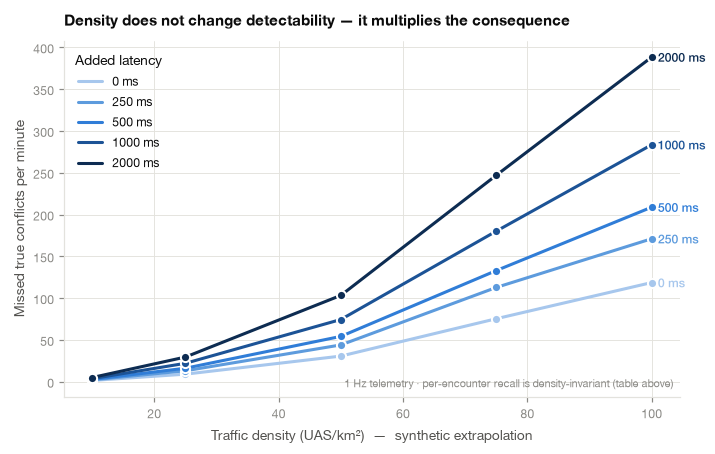

In [8]:
fig, ax = S.plt.subplots(figsize=(6.6, 4.2))
lats = sorted(MISS.latency_ms.unique())
colors = S.sequential_colors(len(lats))
for lat, c in zip(lats, colors):
    g = MISS[MISS.latency_ms == lat].sort_values("density_per_km2")
    ax.plot(g.density_per_km2, g.missed_per_min, color=c, marker="o", ms=6, lw=2,
            markeredgecolor=S.INK["surface"], markeredgewidth=1.3, zorder=3)
    S.direct_label(ax, g.density_per_km2.iloc[-1], g.missed_per_min.iloc[-1], f"{lat:g} ms", c)
ax.set_xlabel("Traffic density (UAS/km²)  —  synthetic extrapolation")
ax.set_ylabel("Missed true conflicts per minute")
ax.set_title("Density does not change detectability — it multiplies the consequence")
ax.legend(handles=[S.plt.Line2D([], [], color=c, lw=2, label=f"{lat:g} ms")
                   for lat, c in zip(lats, colors)],
          title="Added latency", loc="upper left")
S.annotate_note(ax, "1 Hz telemetry · per-encounter recall is density-invariant (table above)")
S.finish(fig, ax); S.save(fig, "F6_missed_conflicts_vs_density"); S.plt.show()

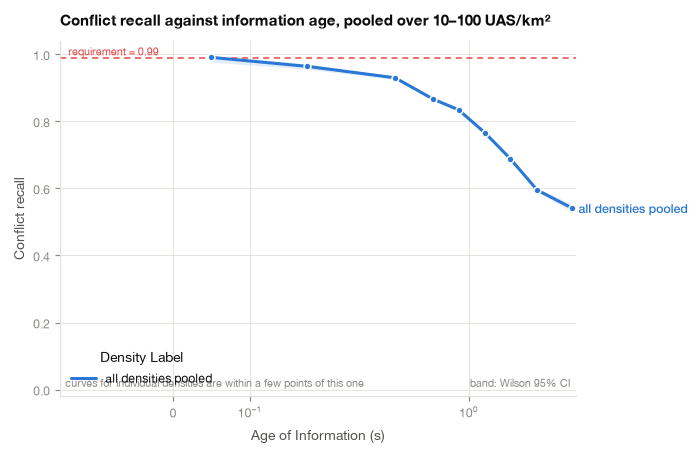

In [9]:
# The density-invariant curve itself, pooled across densities.
pooled = recall_by_aoi(E4)
pooled = pooled[pooled.n_positive >= 30]
from telemetry_freshness.evaluation.statistics import wilson_interval
lh = [wilson_interval(int(r.tp), int(r.n_positive)) for _, r in pooled.iterrows()]
pooled["recall_lo"] = [x[0] for x in lh]; pooled["recall_hi"] = [x[1] for x in lh]
pooled["density_label"] = "all densities pooled"
pooled.to_csv("results/processed/E6_pooled_recall_curve.csv", index=False)

fig, ax = F.fig_recall_vs_aoi(pooled, level_col="density_label", requirement=0.99,
    title="Conflict recall against information age, pooled over 10–100 UAS/km²")
S.annotate_note(ax, "curves for individual densities are within a few points of this one",
                loc="lower left")
S.save(fig, "F6b_pooled_recall_curve"); S.plt.show()

## Which predictor explains the threshold best? (RQ3)

Rank correlation, because the relationships are expected to be monotonic but
not linear.

In [10]:
from telemetry_freshness.evaluation.statistics import spearman_predictors

try:
    PRED = pd.read_csv("results/processed/E5_predictors.csv").groupby("density_per_km2").mean(numeric_only=True).reset_index()
    BYDENS = BYDENS.merge(PRED, on="density_per_km2", how="left")
except FileNotFoundError:
    pass
cands = [c for c in ("density_per_km2","local_mean_100m","local_mean_250m","local_mean_500m",
                     "local_mean_1000m","conflict_pairs_per_min","converging_pairs_per_min")
         if c in BYDENS.columns]

# Correlate within each recall requirement: pooling across requirements would
# mix two different quantities on the y-axis.
for req, g in BYDENS.groupby("min_recall"):
    finite = g.dropna(subset=["aoi_max_safe_s"])
    print(f"--- recall requirement {req:g}  ({len(finite)} finite thresholds) ---")
    if len(finite) >= 3:
        display(spearman_predictors(finite, "aoi_max_safe_s", cands).round(4))
    else:
        print("   too few finite thresholds for a rank correlation; reported descriptively.")
        display(g[["density_per_km2","aoi_max_safe_s","limiting_constraint"]])

--- recall requirement 0.9  (4 finite thresholds) ---


,predictor,spearman_rho,p_value,n
0,density_per_km2,0.7379,0.2621,4
1,local_mean_100m,0.7379,0.2621,4
2,local_mean_250m,0.7379,0.2621,4
3,local_mean_500m,0.7379,0.2621,4
4,local_mean_1000m,0.7379,0.2621,4
5,conflict_pairs_per_min,0.7379,0.2621,4
6,converging_pairs_per_min,0.7379,0.2621,4


--- recall requirement 0.95  (2 finite thresholds) ---
   too few finite thresholds for a rank correlation; reported descriptively.


,density_per_km2,aoi_max_safe_s,limiting_constraint
5,10,NaN,recall
6,25,NaN,recall
7,50,NaN,recall
8,75,0.25,recall
9,100,0.10,recall


--- recall requirement 0.99  (0 finite thresholds) ---
   too few finite thresholds for a rank correlation; reported descriptively.


,density_per_km2,aoi_max_safe_s,limiting_constraint
10,10,NaN,recall
11,25,NaN,recall
12,50,NaN,recall
13,75,NaN,recall
14,100,NaN,recall


## Sensitivity of the threshold to the stated constraints — Figure F7

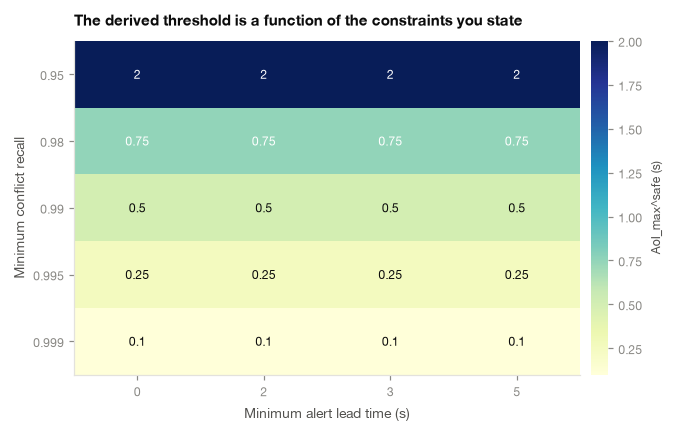

,min_recall,min_lead_s,aoi_max_safe_s,limiting
0,0.950,0.0,2.00,recall
1,0.950,2.0,2.00,recall
2,0.950,3.0,2.00,recall
3,0.950,5.0,2.00,recall
4,0.980,0.0,0.75,recall
5,0.980,2.0,0.75,recall
6,0.980,3.0,0.75,recall
7,0.980,5.0,0.75,recall
8,0.990,0.0,0.50,recall
9,0.990,2.0,0.50,recall


In [11]:
rows = []
for recall_req in (0.95, 0.98, 0.99, 0.995, 0.999):
    for lead_req in (0.0, 2.0, 3.0, 5.0):
        c = SafetyConstraints(min_recall=recall_req, min_lead_time_p95_s=lead_req,
                              min_samples=200, use_confidence_bound=True)
        r = derive_safe_aoi(E1, c)
        rows.append({"min_recall": recall_req, "min_lead_s": lead_req,
                     "aoi_max_safe_s": r.aoi_max_safe_s,
                     "limiting": r.limiting_constraint})
SENS = pd.DataFrame(rows)
SENS.to_csv("results/processed/E6_sensitivity.csv", index=False)

piv = SENS.pivot(index="min_recall", columns="min_lead_s", values="aoi_max_safe_s")
fig, ax = S.plt.subplots(figsize=(6.2, 4.0))
im = ax.imshow(piv.to_numpy(dtype=float), cmap="YlGnBu", aspect="auto")
ax.set_xticks(range(len(piv.columns)), [f"{c:g}" for c in piv.columns])
ax.set_yticks(range(len(piv.index)), [f"{r:g}" for r in piv.index])
ax.set_xlabel("Minimum alert lead time (s)"); ax.set_ylabel("Minimum conflict recall")
ax.set_title("The derived threshold is a function of the constraints you state")
ax.grid(False)
vals = piv.to_numpy(dtype=float)
mid = np.nanmean(vals)
for i in range(vals.shape[0]):
    for j in range(vals.shape[1]):
        v = vals[i, j]
        ax.text(j, i, "—" if not np.isfinite(v) else f"{v:g}", ha="center", va="center",
                fontsize=8, color=S.INK["surface"] if np.isfinite(v) and v > mid else S.INK["primary"])
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02); cb.set_label("AoI_max^safe (s)", fontsize=8)
cb.outline.set_visible(False)
S.finish(fig, ax); S.save(fig, "F7_threshold_sensitivity"); S.plt.show()
display(SENS)

> **How to report this.** The threshold is meaningless without its constraints
> attached. Every figure and table above carries them, and F7 shows the whole
> surface rather than a single number, so a reader can locate the value that
> corresponds to *their* operational requirement.